<a href="https://colab.research.google.com/github/Boran-Sert/SoftITO_Projler/blob/master/Python/16_10_2026_Ders_i%C3%A7i_RNN_%C3%A7al%C4%B1%C5%9Fmas%C4%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np

In [25]:
df = pd.read_csv("/content/Electric_Production.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   DATE        397 non-null    object 
 1   IPG2211A2N  397 non-null    float64
dtypes: float64(1), object(1)
memory usage: 6.3+ KB


In [38]:
import matplotlib.pyplot as plt         # Grafik çizmek için
from sklearn.preprocessing import StandardScaler

# Veri setindeki sütunu alıyoruz
seri_orijinal = df["IPG2211A2N"].values.reshape(-1, 1)

# Veriyi StandardScaler ile standartlaştırıyoruz (ortalama=0, varyans=1)
scaler = StandardScaler()
seri = scaler.fit_transform(seri_orijinal).flatten()

PENCERE = 30                            # Model geçmişteki 40 adıma bakacak

X, y = [] , []                           # Girdi pencereleri ve hedefler için boş listeler
for i in range(len(seri) - PENCERE):
    X.append(seri[i:i + PENCERE])       # Girdi: i..i+39 arasındaki 40 değer
    y.append(seri[i + PENCERE])         # Hedef: hemen ardından gelen 41. değer

X = np.array(X, dtype="float32")[..., None]
y = np.array(y, dtype="float32")[:, None]

bolme = int(0.8 * len(X))               # Verinin %80'i eğitim, %20'si test
X_egitim_np, y_egitim_np = X[:bolme], y[:bolme]
X_test_np,   y_test_np   = X[bolme:], y[bolme:]

print("X şekli:", X.shape, "| y şekli:", y.shape)
print("Eğitim:", X_egitim_np.shape[0], "örnek | Test:", X_test_np.shape[0], "örnek")

X şekli: (367, 30, 1) | y şekli: (367, 1)
Eğitim: 293 örnek | Test: 74 örnek


In [39]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # TensorFlow'un uzun bilgi mesajlarını gizle
import tensorflow as tf                  # Keras'ın üzerinde çalıştığı motor
from tensorflow import keras             # Yüksek seviyeli model API'si
from tensorflow.keras import layers      # Hazır katmanlar: SimpleRNN, Dense ...

tf.random.set_seed(42)                   # Rastgele başlangıç ağırlıkları tekrarlanabilir olsun

keras_model = keras.Sequential([         # Katmanları sırayla dizen basit model yapısı
    keras.Input(shape=(PENCERE, 1)),     # Girdi: 20 zaman adımı × 1 özellik (batch boyutu yazılmaz)
    layers.SimpleRNN(
        64,                              # Gizli durum boyutu H = 32
        activation="tanh",               # Aktivasyon (varsayılan zaten tanh)
        return_sequences=False),         # False: sadece SON h_t döner (B, 32)
                                         # True olsaydı her adımın h_t'si dönerdi (B, 20, 32)
    layers.Dense(1)                      # Son gizli durumu tek bir sayıya çevir (tahmin)
])
keras_model.summary()                    # Katmanları ve parametre sayılarını yazdır

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_5 (SimpleRNN)        │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
keras_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3,              # Öğrenme hızı
        clipnorm=1.0),                   # Gradyan kırpma: patlayan gradyanlara karşı koruma
    loss="mse",                          # Ortalama kare hata
    metrics=["mae"])                     # Ek olarak ortalama mutlak hatayı da izle

gecmis = keras_model.fit(                # zero_grad → ileri → kayıp → backward → step: hepsi burada
    X_egitim_np, y_egitim_np,            # Eğitim verisi (NumPy dizileri doğrudan verilebilir)
    epochs=20,                           # 20 tur
    batch_size=66,                       # Her adımda 64 örnek
    validation_split=0.1,                # Eğitim verisinin %10'unu doğrulama için ayır
    shuffle=True,                        # Her epoch'ta karıştır
    verbose=2)                           # Her epoch için tek satır özet yazdır

Epoch 1/20
4/4 - 2s - 455ms/step - loss: 1.0655 - mae: 0.8430 - val_loss: 0.6427 - val_mae: 0.6770
Epoch 2/20
4/4 - 0s - 33ms/step - loss: 0.2230 - mae: 0.3807 - val_loss: 0.1668 - val_mae: 0.3158
Epoch 3/20
4/4 - 0s - 29ms/step - loss: 0.0932 - mae: 0.2465 - val_loss: 0.1205 - val_mae: 0.2833
Epoch 4/20
4/4 - 0s - 31ms/step - loss: 0.0713 - mae: 0.2096 - val_loss: 0.1463 - val_mae: 0.3242
Epoch 5/20
4/4 - 0s - 29ms/step - loss: 0.0586 - mae: 0.1948 - val_loss: 0.1335 - val_mae: 0.3019
Epoch 6/20
4/4 - 0s - 28ms/step - loss: 0.0481 - mae: 0.1726 - val_loss: 0.1332 - val_mae: 0.2897
Epoch 7/20
4/4 - 0s - 31ms/step - loss: 0.0439 - mae: 0.1643 - val_loss: 0.1540 - val_mae: 0.3174
Epoch 8/20
4/4 - 0s - 31ms/step - loss: 0.0401 - mae: 0.1593 - val_loss: 0.1215 - val_mae: 0.2855
Epoch 9/20
4/4 - 0s - 31ms/step - loss: 0.0374 - mae: 0.1526 - val_loss: 0.1253 - val_mae: 0.2943
Epoch 10/20
4/4 - 0s - 39ms/step - loss: 0.0357 - mae: 0.1492 - val_loss: 0.1291 - val_mae: 0.2954
Epoch 11/20
4/4 - 

In [41]:
k_test_mse, k_test_mae = keras_model.evaluate(X_test_np, y_test_np, verbose=0)  # Ölçekli test kaybı
print(f"Keras Test MSE (Standartlaştırılmış): {k_test_mse:.5f} | Test MAE (Standartlaştırılmış): {k_test_mae:.5f}\n")

k_test_tahmin_olcekli = keras_model.predict(X_test_np, verbose=0)    # Ölçekli tahminler

# Tahminleri ve gerçek değerleri orijinal ölçeğe geri döndürüyoruz
k_test_tahmin = scaler.inverse_transform(k_test_tahmin_olcekli)
y_test_gercek = scaler.inverse_transform(y_test_np)

# Orijinal ölçekteki gerçek hata değerlerini hesaplama
orijinal_mse = np.mean((y_test_gercek - k_test_tahmin) ** 2)
orijinal_mae = np.mean(np.abs(y_test_gercek - k_test_tahmin))
print(f"Gerçek Ölçekte Test MSE: {orijinal_mse:.5f} | Test MAE: {orijinal_mae:.5f}\n")

for gercek, tahmin in zip(y_test_gercek[:5, 0], k_test_tahmin[:5, 0]):
    print(f"Gerçek: {gercek:+.3f}   Tahmin: {tahmin:+.3f}")

Keras Test MSE (Standartlaştırılmış): 0.07254 | Test MAE (Standartlaştırılmış): 0.19794

Gerçek Ölçekte Test MSE: 17.13397 | Test MAE: 3.04201

Gerçek: +107.331   Tahmin: +107.384
Gerçek: +111.965   Tahmin: +112.080
Gerçek: +103.368   Tahmin: +104.979
Gerçek: +93.577   Tahmin: +96.899
Gerçek: +87.557   Tahmin: +88.641


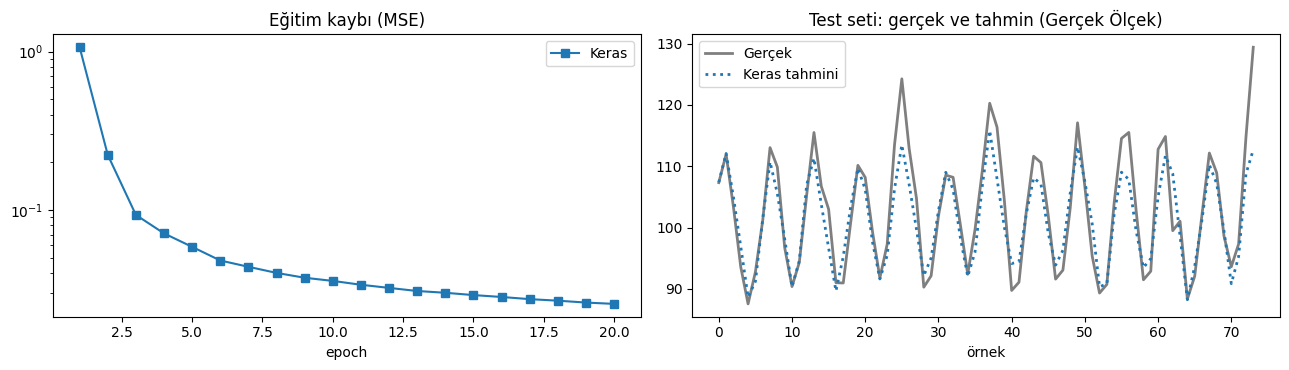

Keras Gerçek Ölçekte Test MSE: 17.13397


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

# Sol: eğitim kaybı eğrileri
axes[0].plot(range(1, 21), gecmis.history["loss"], marker="s", label="Keras")
axes[0].set_yscale("log")
axes[0].set_title("Eğitim kaybı (MSE)"); axes[0].set_xlabel("epoch"); axes[0].legend()

# Sağ: test setinin ilk 150 noktasında gerçek vs tahmin (Gerçek ölçekte çizdiriyoruz)
n = 150
axes[1].plot(y_test_gercek[:n, 0], color="black", lw=2, alpha=0.5, label="Gerçek")
axes[1].plot(k_test_tahmin[:n, 0], ":", lw=2, label="Keras tahmini")
axes[1].set_title("Test seti: gerçek ve tahmin (Gerçek Ölçek)"); axes[1].set_xlabel("örnek"); axes[1].legend()

plt.tight_layout(); plt.show()

print(f"Keras Gerçek Ölçekte Test MSE: {orijinal_mse:.5f}")